## Submission Instructions

In [1]:
# Imports necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib

# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="rocket", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

Seed generated: 1027714457


## Q1.0 Dataset Generation

The following class implementation includes all methods required for **Q1**. The comments written showcase the split between various methods for the given questions. 

In [2]:
class StudentDataset:
# Q1.0 Dataset Generation 
    def __init__(self, num_students=10000):
        self.num_students = num_students
        self.data = self.assemble_dataframe()

    def get_full_dataframe(self) -> pd.DataFrame:
        return self.data

    def generate_gender(self) -> list[str]:
        return rng.choice(["Male", "Female", "Other"],
            size=self.num_students, p=[0.65, 0.33, 0.02]
        ).tolist()

    def generate_major(self) -> list[str]:
        return rng.choice(
            ["B.Tech", "MS", "PhD"],
            size=self.num_students, p=[0.7, 0.2, 0.1]
        ).tolist()

    def generate_program(self, majors: list[str]) -> list[str]:
        programs = []
        for m in majors:
            if m == "B.Tech":
                prog = rng.choice(["CSE", "ECE", "CHD", "CND"], p=[0.4, 0.4, 0.1, 0.1])
            elif m == "MS":
                prog = rng.choice(["CSE", "ECE", "CHD", "CND"], p=[0.3, 0.3, 0.2, 0.2])
            else:
                prog = rng.choice(["CSE", "ECE", "CHD", "CND"], p=[0.25, 0.25, 0.25, 0.25])
            programs.append(prog)
        return programs

    def generate_gpa(self, majors: list[str]) -> list[float]:
        gpas = []
        for m in majors:
            if m == "B.Tech":
                gpa = rng.normal(7.0, 1.0)
            elif m == "MS":
                gpa = rng.normal(8.0, 0.7)
            else:
                gpa = rng.normal(8.3, 0.5)
            gpa = np.clip(gpa, 4.0, 10.0)
            gpas.append(gpa)
        return gpas

    def assemble_dataframe(self) -> pd.DataFrame:
        genders = self.generate_gender()
        majors = self.generate_major()
        programs = self.generate_program(majors)
        gpas = self.generate_gpa(majors)
        return pd.DataFrame({"Gender": genders, "Major": majors,
                             "Program": programs, "GPA": gpas})

# Q1.1 Dataset Analysis
    # (a) Visualizations
    def plot_gender_distribution(self):
        sns.catplot(data=self.data, x="Gender", kind="count")
        plotinfo("Gender Distribution", "Gender", "No. of Students")

    def plot_major_distribution(self):
        sns.catplot(data=self.data, x="Major", kind="count")
        plotinfo("Major Distribution", "Major", "No. of Students")

    def plot_program_distribution(self):
        sns.catplot(data=self.data, x="Program", kind="count")
        plotinfo("Program Distribution", "Program", "No. of Students")

    def plot_gpa_distribution(self, bins: int = 20):
        sns.histplot(data=self.data, x="GPA", bins=bins, kde=True)
        plotinfo("GPA Distribution", "Grade", "No. of Students")

    def plot_program_by_major(self):
        sns.catplot(data=self.data, x="Program", hue="Major",
                    kind="count", height=5, aspect=1.5)
        plotinfo("Program Conditioned on Major", "Program", "Number of Students")

    def plot_gpa_by_major(self, bins: int = 20):
        sns.histplot(data=self.data, x="GPA", hue="Major",
                     bins=bins, alpha=0.25, multiple="layer", kde=True)
        plotinfo("GPA Conditioned on Major", "GPA", "Number of Students")

    def plot_gpa_by_program(self, bins: int = 20):
        sns.histplot(data=self.data, x="GPA", hue="Program",
                     bins=bins, alpha=0.25, multiple="layer", kde=True)
        plotinfo("GPA Conditioned on Program", "Program", "Number of Students")

    def plot_gpa_by_program_and_major(self):
        sns.violinplot(data=self.data, x="Major", y="GPA", hue="Program",
                       split=False, inner="quartile")
        plotinfo("GPA Conditioned on Program & Major", "Major", "GPA")

    def plot_sampled_dataset(self, n: int = 100, bins: int = 20, seed: int = seed):
        sample = self.data.sample(n=n, random_state=seed)
        full = self.data

        fig, axes = plt.subplots(3, 2, figsize=(14, 14))
        sns.countplot(data=sample, x="Gender", ax=axes[0,0])
        coordplot(axes[0,0], "Sampled Gender Distribution", "Gender", "No. of Students")
        sns.countplot(data=sample, x="Major", ax=axes[0,1])
        coordplot(axes[0,1], "Sampled Major Distribution", "Major", "No. of Students")
        sns.countplot(data=sample, x="Program", ax=axes[1,0])
        coordplot(axes[1,0], "Sampled Program Distribution", "Program", "No. of Students")
        
        sns.histplot(sample["GPA"], bins=bins, kde=True, alpha=0.6, ax=axes[1,1])
        coordplot(axes[1,1], "Sampled GPA Distribution", "GPA", "No. of Students")
        sns.histplot(x="Gender", data=full, stat="probability", discrete=True,
                     alpha=0.4, ax=axes[2,0], label="Full")
        sns.histplot(x="Gender", data=sample, stat="probability", discrete=True,
                     alpha=0.4, ax=axes[2,0], label="Sample")
        coordplot(axes[2,0], "Gender Distribution (Normalized)", "Gender", "Proportion")
        axes[2,0].legend()
        sns.histplot(full["GPA"], bins=bins, stat="density", kde=True,
                     alpha=0.4, ax=axes[2,1], label="Full")
        sns.histplot(sample["GPA"], bins=bins, stat="density", kde=True,
                     alpha=0.4, ax=axes[2,1], label="Sample")
        coordplot(axes[2,1], "GPA Distribution (Normalized)", "GPA", "Density")
        axes[2,1].legend()
        plt.text(0.95, -0.02, "sudhanva.joshi", ha="right", va="top",
                 transform=plt.gcf().transFigure, fontsize=10,
                 color="gray", alpha=0.7)
        plt.tight_layout()
        plt.show()

    def plot_entire_dataset_summary(self):
        features = ["GPA", "Major", "Program", "Gender"]
        fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(18, 18))
        for i, row_var in enumerate(features):
            for j, col_var in enumerate(features):
                ax = axes[i, j]
                if i < j:
                    ax.axis('off')
                    continue
                if i == j:
                    if self.data[row_var].dtype == 'object':
                        sns.countplot(data=self.data, x=row_var, ax=ax)
                    else:
                        sns.kdeplot(data=self.data, x=row_var, ax=ax, fill=True, linewidth=2)
                
                else:
                    if self.data[row_var].dtype == 'object' and self.data[col_var].dtype == 'object':
                        # Create a contingency table and plot as a heatmap
                        counts = pd.crosstab(self.data[row_var], self.data[col_var])
                        sns.heatmap(counts, ax=ax, annot=True, fmt='d', cmap="flare")
                    else:
                        if self.data[row_var].dtype == 'object':
                            cat_var, num_var = row_var, col_var
                        else:
                            cat_var, num_var = col_var, row_var
                        sns.boxplot(data=self.data, x=cat_var, y=num_var, ax=ax)
        fig.suptitle("Dataset Feature Summary", fontsize=24, y=0.95)
        plt.text(0.95, -0.02, "sudhanva.joshi", ha="right", va="top",
                transform=plt.gcf().transFigure, fontsize=10, color="gray", alpha=0.7)
        plt.tight_layout(rect=[0, 0, 1, 0.93])
        plt.show()

    # (b) GPA Summary Statistics
    def gpa_mean_std(self) -> tuple[float, float]:
        mean = self.data["GPA"].mean()
        std = self.data["GPA"].std()
        return mean, std

    # (c) Program-Major Combinations
    def count_students_per_program_major_pair(self):
        return self.data.groupby(["Program", "Major"]).size().reset_index(name='Count')

    def visualize_students_per_program_major_pair(self, count):
        pivot = count.pivot(index="Program", columns="Major", values="Count")
        pivot['Total'] = pivot.sum(axis=1)
        total_row = pivot.sum(axis=0).to_frame().T
        total_row.index = ['Total']
        pivot = pd.concat([pivot, total_row])
        sns.heatmap(pivot, annot=True, fmt=".2f", cmap="flare")
        plotinfo("Students per Program-Major Pair", "Program", "Major")


# Q1.2 Simple vs Stratified Sampling
    def get_gpa_mean_std_random(self, n: int = 500, repeats: int = 50) -> tuple[float, float]:
        means = []
        stds = []
        for _ in range(repeats):
            sample = self.data.sample(n, random_state=rng)
            means.append(sample["GPA"].mean())
            stds.append(sample["GPA"].std())
        return (means, stds)

    def get_gpa_mean_std_stratified(self, n: int = 500, repeats: int = 50, col: str = "Major") -> tuple[float, float]:
        means = []
        stds = []
        strata_proportions = self.data[col].value_counts(normalize=True)
        for _ in range(repeats):
            stratified_samples_list = []
            for stratum, proportion in strata_proportions.items():
                stratum_data = self.data[self.data[col] == stratum]
                stratum_n = int(round(proportion * n))
                stratified_samples_list.append(
                    stratum_data.sample(stratum_n, random_state=rng))
            final_sample = pd.concat(stratified_samples_list)
            
            means.append(final_sample["GPA"].mean())
            stds.append(final_sample["GPA"].std())

        return (means, stds)


# Q1.3 Gender-Balanced Cohort
    def get_gender_balanced_counts(self, column: str, n: int = 300, repeats: int = 5) -> list[dict[str, int]]:
        category = self.data[column].unique()
        per_gender = n // len(category)
        results = []
        for _ in range(repeats):
            sample_parts = []
            for g in category:
                sample_parts.append(
                    self.data[self.data[column] == g].sample(per_gender, replace=True, random_state=rng)
                )
            final_sample = pd.concat(sample_parts)
            counts_dict = final_sample[column].value_counts().to_dict()
            results.append(counts_dict)
        return results

    def sample_gender_uniform_random(self, column, n: int = 300, repeats: int = 5) -> list[dict[str, int]]:
        category = self.data[column].unique()
        results = []
        for _ in range(repeats):
            counts = {g: 0 for g in category}
            for _ in range(n):
                g = rng.choice(category)
                _ = self.data[self.data[column] == g].sample(1, replace=True, random_state=rng)
                counts[g] += 1
            results.append(counts)
        return results

    def plot_avg_max_gender_diff_vs_sample_size(self, sample_sizes: list[int], repeats: int = 10) -> None:
        avg_diffs = []
        for n in sample_sizes:
            diffs = []
            for _ in range(repeats):
                counts = self.sample_gender_uniform_random("Gender", n=n, repeats=1)[0]
                max_count = max(counts.values())
                min_count = min(counts.values())
                rel_diff = (max_count - min_count) / n
                diffs.append(rel_diff)
            avg_diffs.append(np.mean(diffs))
        plt.figure(figsize=(8, 5))
        plt.bar([str(s) for s in sample_sizes], avg_diffs, width=0.6)
        plotinfo("Average Max Relative Gender Difference vs Sample Size",
                 "Number of Students Sampled", "Average Max Relative Difference")


# Q1.4 GPA-Uniform Cohort
    def sample_gpa_uniform(self, n: int = 100, bins: int = 10) -> pd.DataFrame:
        data_with_bins = self.data.copy()
        data_with_bins['gpa_bin'] = pd.cut(data_with_bins['GPA'], bins=bins, labels=False)
        bin_categories = list(range(bins))
        sampled_students_list = []
        for _ in range(n):
            chosen_bin = rng.choice(bin_categories)
            students_in_bin = data_with_bins[data_with_bins['gpa_bin'] == chosen_bin]
            if not students_in_bin.empty:
                student_sample = students_in_bin.sample(1, replace=True, random_state=rng)
                sampled_students_list.append(student_sample)
        final_sample = pd.concat(sampled_students_list).drop(columns=['gpa_bin'])
        return final_sample

    def plot_gpa_histogram_comparison(self, sampled_df: pd.DataFrame) -> None:
        plt.figure(figsize=(12, 7))
        sns.histplot(self.data['GPA'], bins=10, stat='density', 
                    label='Original Dataset', kde=True)
        sns.histplot(sampled_df['GPA'], bins=10, stat='density', 
                    label='Sampled Students', kde=True)
        plt.legend()
        plotinfo("Comparison of GPA Distributions", "GPA", "Density")


# Q1.5 Program-Major Balanced Cohort
    def sample_program_major_balanced(self, n: int = 60) -> pd.DataFrame:
        valid_combinations = self.data.groupby(['Program', 'Major']).size().reset_index()[['Program', 'Major']]
        sampled_students_list = []
        for _ in range(n):
            chosen_combination = valid_combinations.sample(1, random_state=rng).iloc[0]
            student_sample = self.data[
                (self.data['Program'] == chosen_combination['Program']) &
                (self.data['Major'] == chosen_combination['Major'])
            ].sample(1, replace=True, random_state=rng)
            sampled_students_list.append(student_sample)
        return pd.concat(sampled_students_list)
        
    def show_program_major_counts_and_heatmap(self, sampled_df: pd.DataFrame) -> None:
        counts = sampled_df.groupby(['Program', 'Major']).size().reset_index(name='Count')
        print("Counts of all Program-Major Combinations in Sample")
        print(counts.to_string(index=False))
        print("\n")
        pivot = pd.pivot_table(counts, values='Count', index='Major', columns='Program', fill_value=0)
        plt.figure(figsize=(10, 8))
        sns.heatmap(pivot, annot=True, fmt=".2f", cmap="flare")
        plotinfo(
            title="Heatmap of Sampled Students per Program-Major Pair",
            x="Major", y="Program")

### Dataset Generation Cell must be run only once. 

In [3]:
# Generate the dataset and get the full DataFrame. Needs to be saved for other questions.
dataset = StudentDataset(10000)
df = dataset.get_full_dataframe()

## Q1.1 Dataset Analysis
### (a) Visualizations

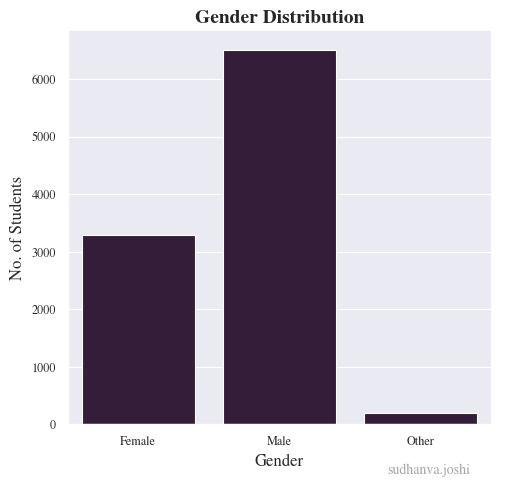

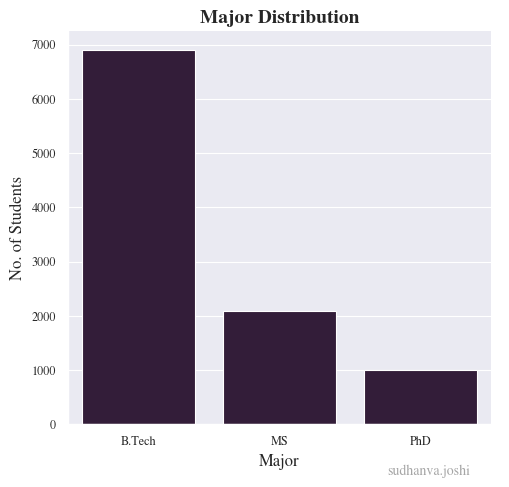

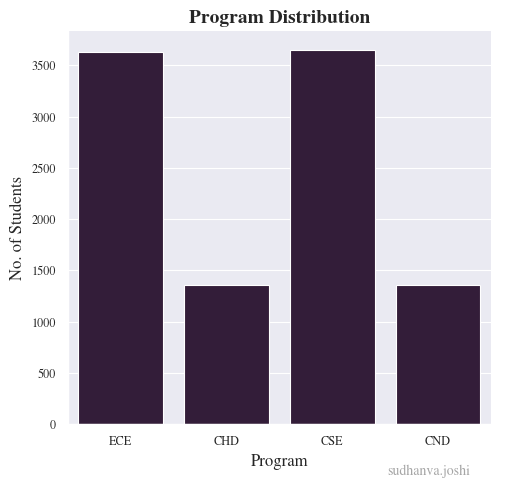

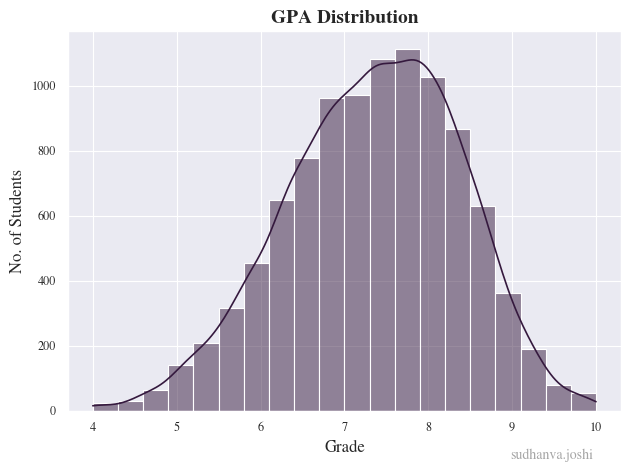

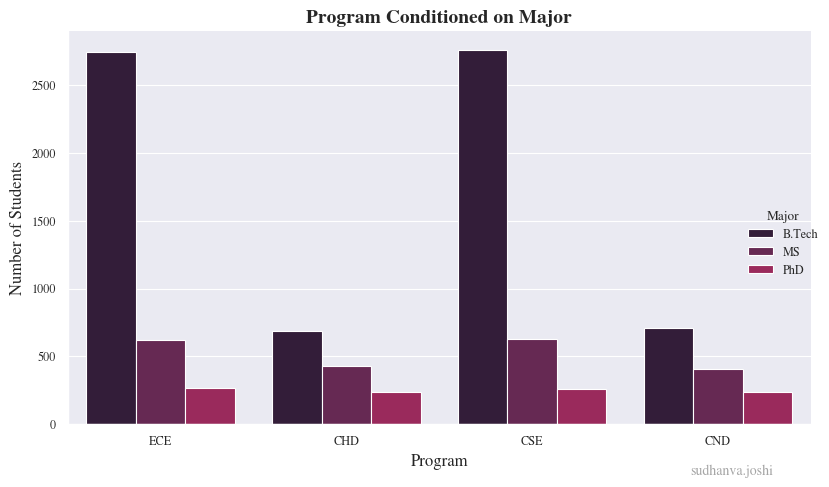

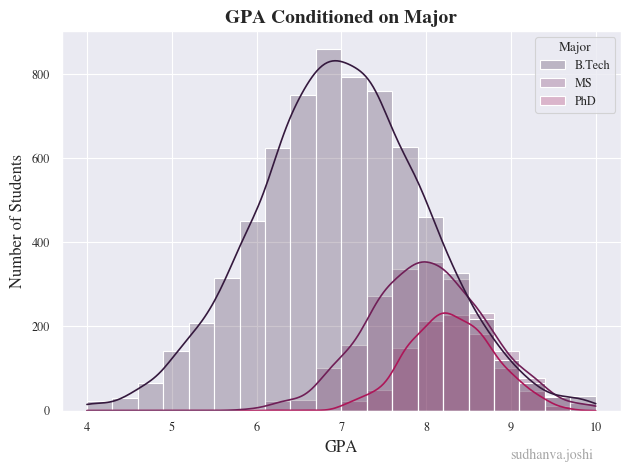

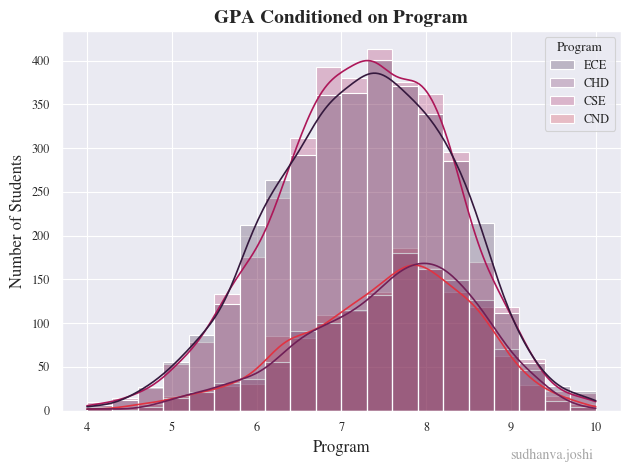

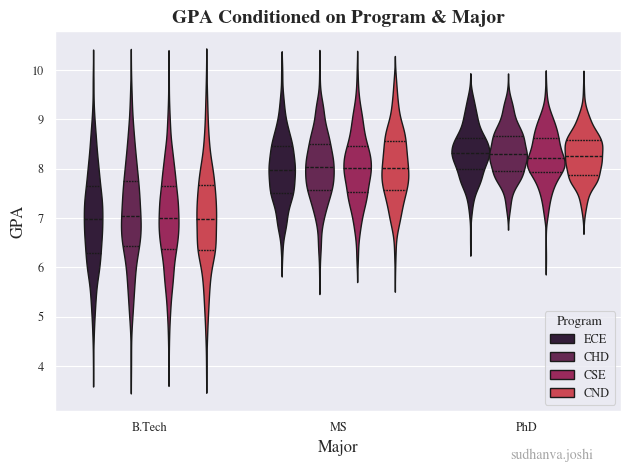

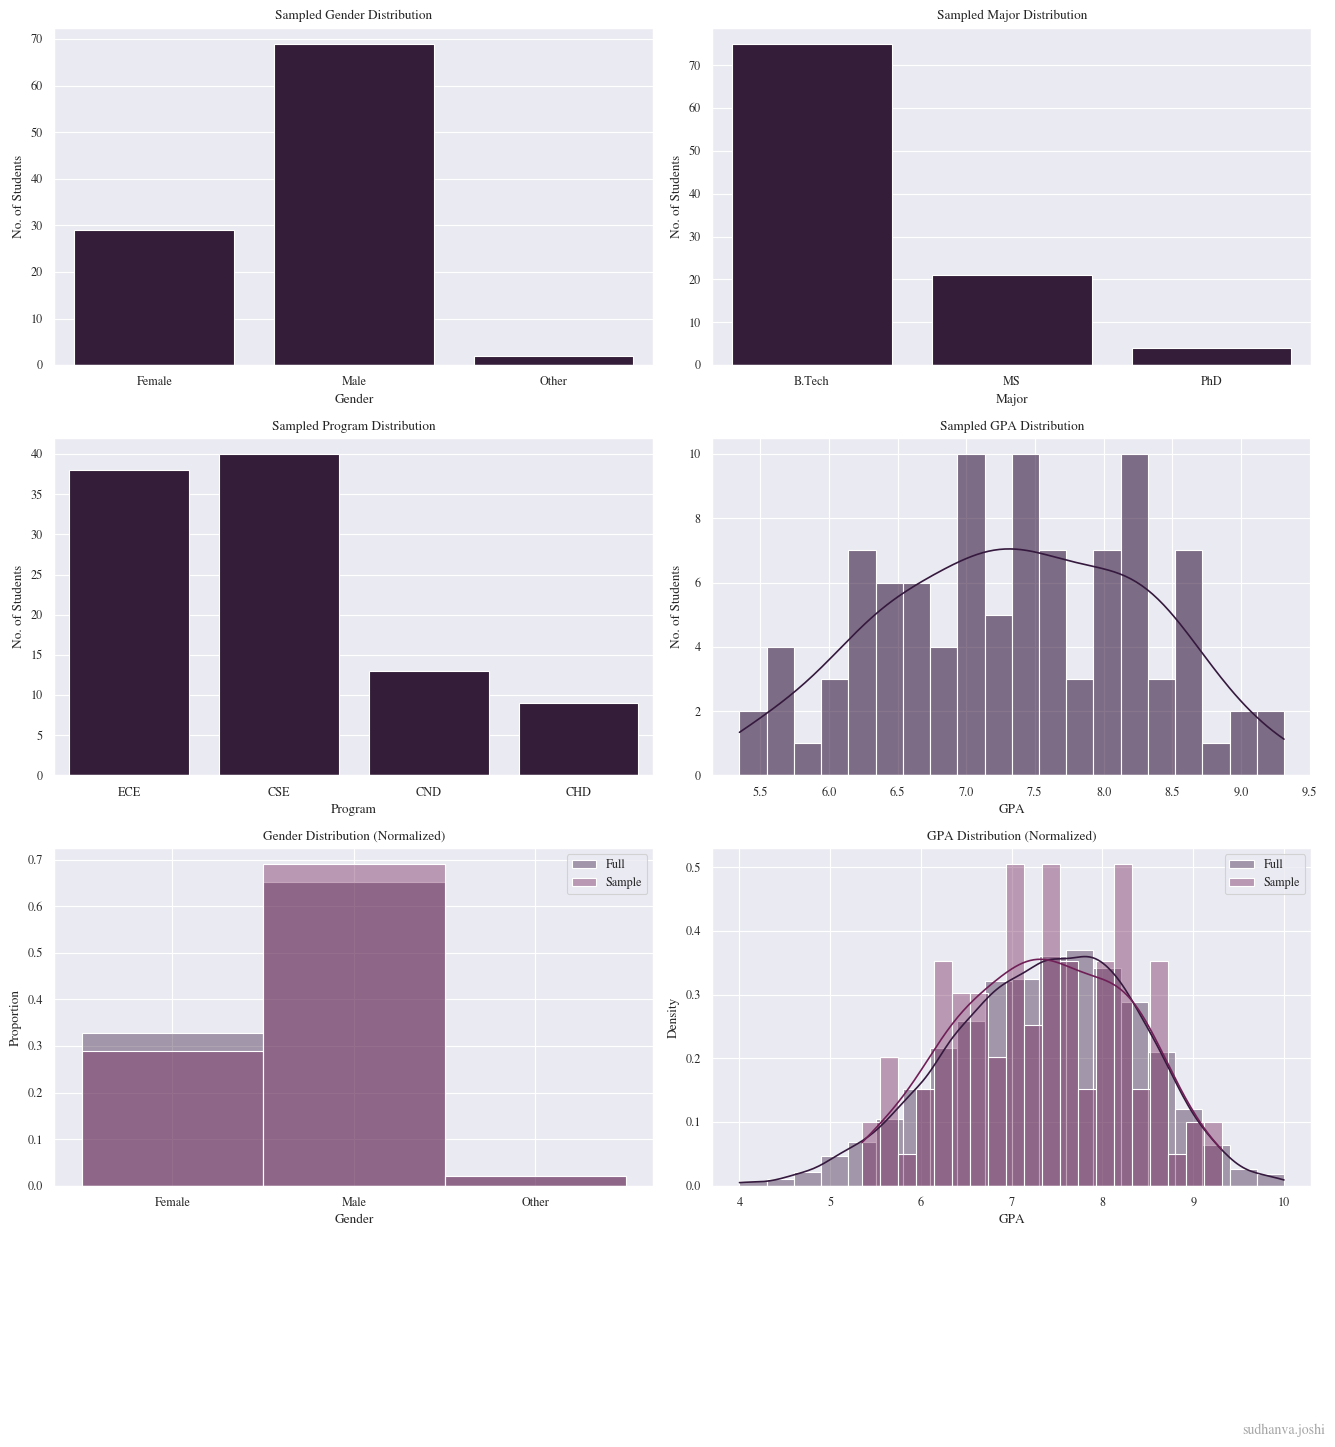

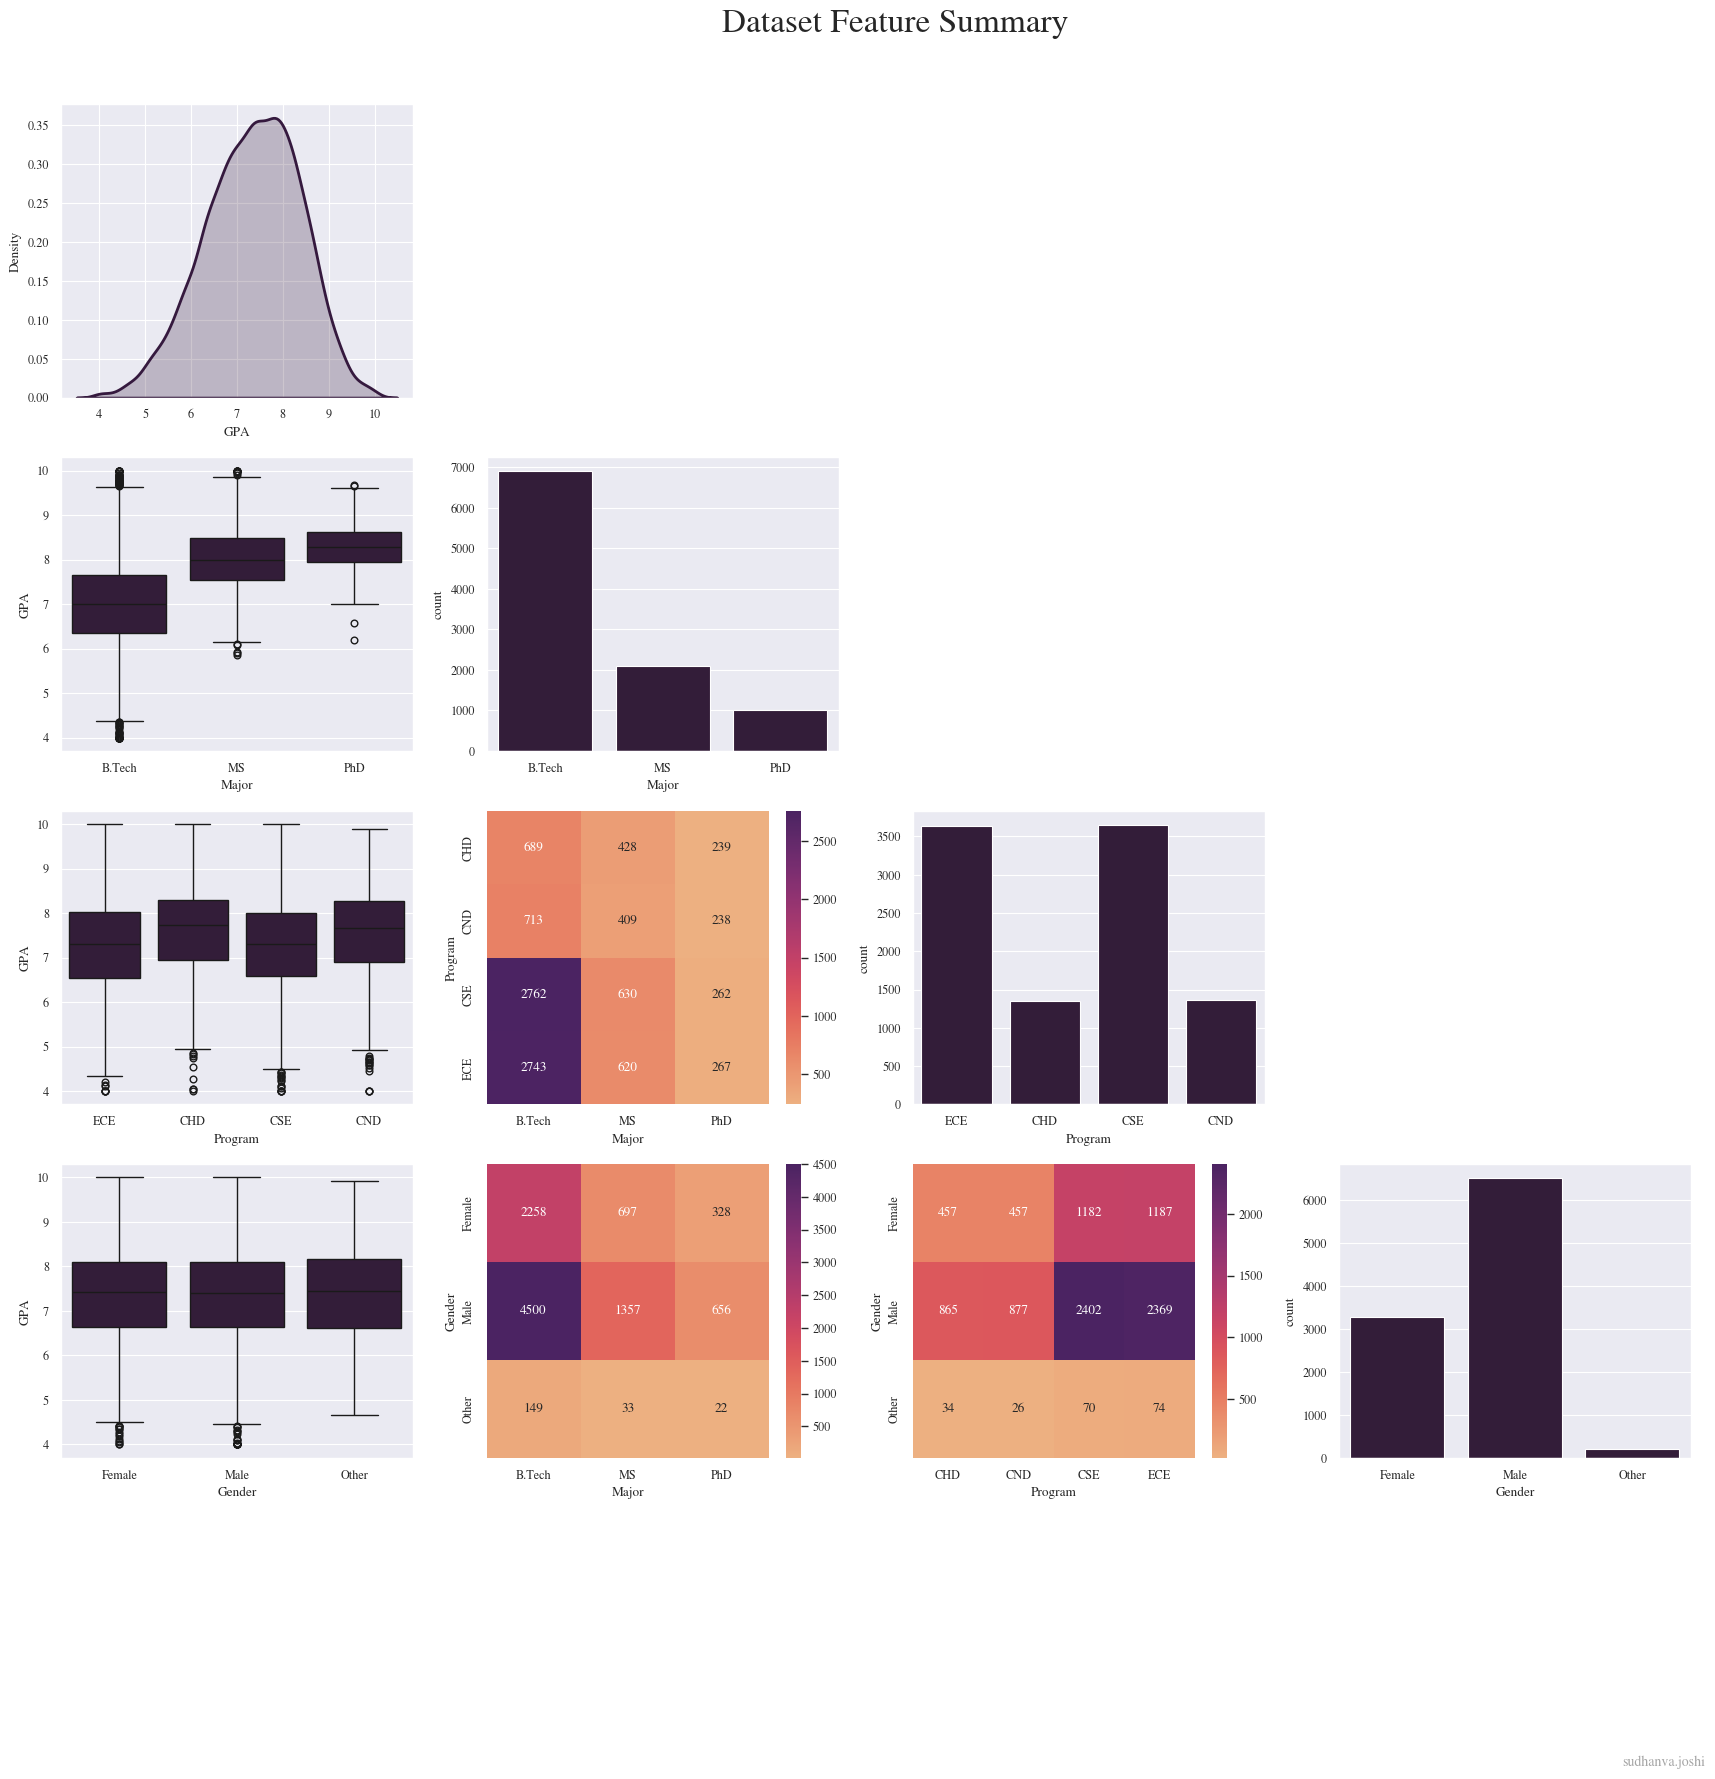

In [4]:
dataset.plot_gender_distribution()
dataset.plot_major_distribution()
dataset.plot_program_distribution()
dataset.plot_gpa_distribution()

dataset.plot_program_by_major()
dataset.plot_gpa_by_major()
dataset.plot_gpa_by_program()
dataset.plot_gpa_by_program_and_major()

dataset.plot_sampled_dataset()
dataset.plot_entire_dataset_summary()

### (b) GPA Summary Statistics
The mean is approximately within bounds of the *Gaussian Distributions with the highest and lowest mean* given that no major greatly dominates over any other in this context *(Although B.Tech has the highest representation here)*.

As all 3 Distributions have difference variations, the final **Standard Deviation** leans closest toward the B.Tech variance and is greater than it.

In [5]:
mean, std = dataset.gpa_mean_std()
print("Mean = ", mean)
print("Standard Deviation = ", std)

Mean =  7.34323444310022
Standard Deviation =  1.038141783725258


### (c) Program-Major Combinations

The number of students in each **program-major** combination are visualized in the output heatmap. A notable observation is that enrollments decrease as the programs become more advanced (B.Tech, MS, PhD).

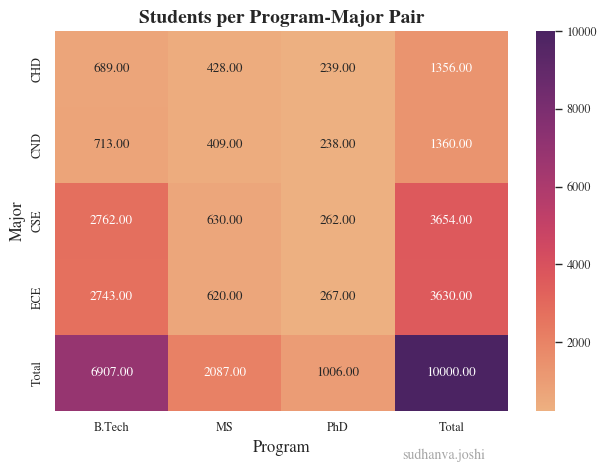

In [6]:
dataset.visualize_students_per_program_major_pair(dataset.count_students_per_program_major_pair())

## Q1.2 Simple vs Stratified Sampling
It is observed that **stratified sampling** yields a dataset that resembles the original full dataset more closely than a dataset and has a lower standard deviation than that based on *random sampling*.

This is due to the fact that each feature is represented more accurately and proportionally in stratified sampling. 

In [7]:
random_means, random_stds = dataset.get_gpa_mean_std_random()
stratified_means, stratified_stds = dataset.get_gpa_mean_std_stratified()

avg_of_random_means = np.mean(random_means)
avg_of_stratified_means = np.mean(stratified_means)

std_of_random_means = np.std(random_means)
std_of_stratified_means = np.std(stratified_means)

print("Mean of Random Means: ", avg_of_random_means)
print("Mean of Stratified Means: ", avg_of_stratified_means)

print("Standard Deviation of Random Means): ", std_of_random_means)
print("Standard Deviation of Stratified Means): ", std_of_stratified_means)

Mean of Random Means:  7.349954560181161
Mean of Stratified Means:  7.350905728785545
Standard Deviation of Random Means):  0.04678801532928623
Standard Deviation of Stratified Means):  0.03506569110061807


## Q1.3 Gender-Balanced Cohort
The general trend of average maximum relative difference is decreasing. 

This is because as the sample size increases, the effect of random picks dominating the sample set goes down, and the distribution more-or-less converges to an equiprobable distribution in the case of our sampling strategy.

Gender Representation, Equal Sampling Size
Run Number 1
{'Female': 100, 'Male': 100, 'Other': 100}
Run Number 2
{'Female': 100, 'Male': 100, 'Other': 100}
Run Number 3
{'Female': 100, 'Male': 100, 'Other': 100}
Run Number 4
{'Female': 100, 'Male': 100, 'Other': 100}
Run Number 5
{'Female': 100, 'Male': 100, 'Other': 100}


Gender Representation, Sampling Strategy A
Run Number 1
{'Female': 104, 'Male': 84, 'Other': 112}
Run Number 2
{'Female': 103, 'Male': 80, 'Other': 117}
Run Number 3
{'Female': 92, 'Male': 103, 'Other': 105}
Run Number 4
{'Female': 101, 'Male': 102, 'Other': 97}
Run Number 5
{'Female': 92, 'Male': 105, 'Other': 103}


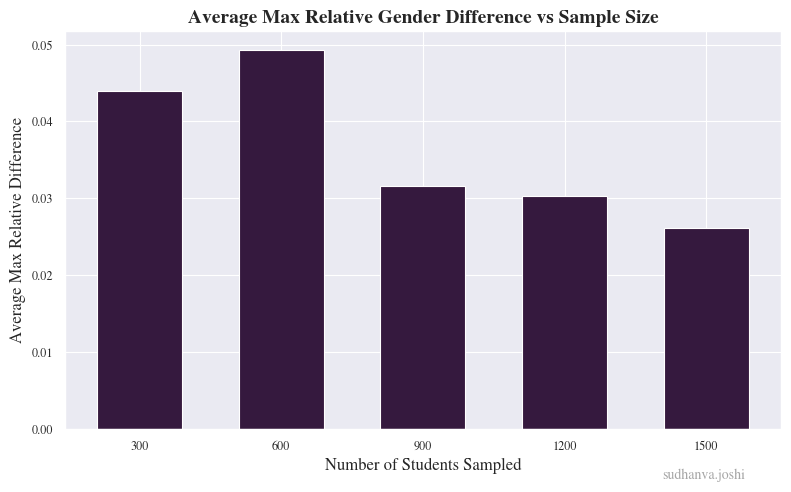

In [8]:
equal_gender_samples = dataset.get_gender_balanced_counts("Gender", n=300, repeats=5)
print("Gender Representation, Equal Sampling Size")
for i, counts_dict in enumerate(equal_gender_samples):
    print(f"Run Number {i+1}")
    print(counts_dict) 
print("\n")
print("Gender Representation, Sampling Strategy A")
strategy_a_counts = dataset.sample_gender_uniform_random("Gender", n=300, repeats=5)
for i, counts_dict in enumerate(strategy_a_counts):
    print(f"Run Number {i+1}")
    print(counts_dict)

sample_sizes = [300, 600, 900, 1200, 1500]
dataset.plot_avg_max_gender_diff_vs_sample_size(sample_sizes)


## Q1.4 GPA-Uniform Cohort
Sampling is done with replacement to better represent cases where enough data points do not exist with the desired features in the full dataset *(in this case, GPA bin)*. Additionally, this represents *"true"* random sampling in some sense, since the dataset to pick from remains intact.

As expected, this does not provide a perfectly uniform sampling, but is a mediocre attempt at doing so. We can expect this strategy to improve as the sampling size increases.

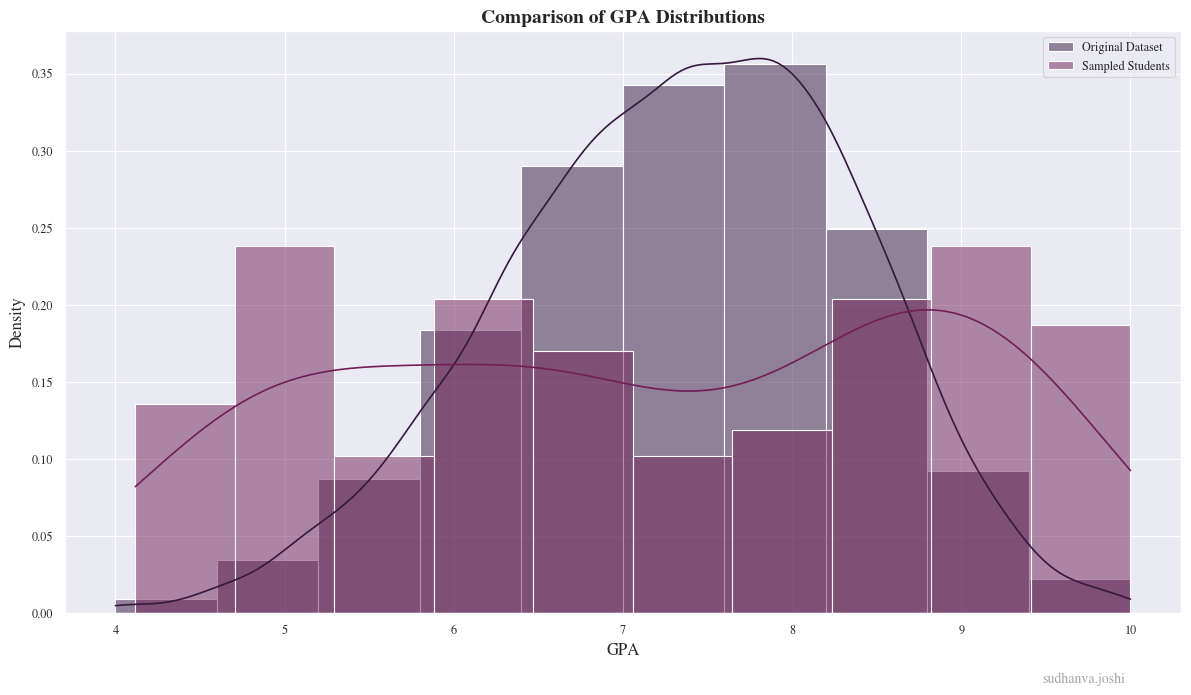

In [9]:
gpa_uniform_cohort = dataset.sample_gpa_uniform()
dataset.plot_gpa_histogram_comparison(gpa_uniform_cohort)

## Q1.5 Program-Major Balanced Cohort
Similar to **Q1.4**, sampling is done with replacement to better represent cases where enough data points do not exist with the desired features in the full dataset *(in this case, program-pair combinations)*.

The sample size of 60 is low enough to be affected by sampling to not be balanced, which may swing distribution in favour of any particular program-major pair. This can be mitigated by fixing the program-major sizes to *60/(all unique combinations) = 5* students per combination, and then sampling 5 times from each combination. 

Counts of all Program-Major Combinations in Sample
Program  Major  Count
    CHD B.Tech      5
    CHD     MS      4
    CHD    PhD      6
    CND B.Tech      5
    CND     MS      4
    CND    PhD      9
    CSE B.Tech      4
    CSE     MS      6
    CSE    PhD      7
    ECE B.Tech      5
    ECE     MS      3
    ECE    PhD      2




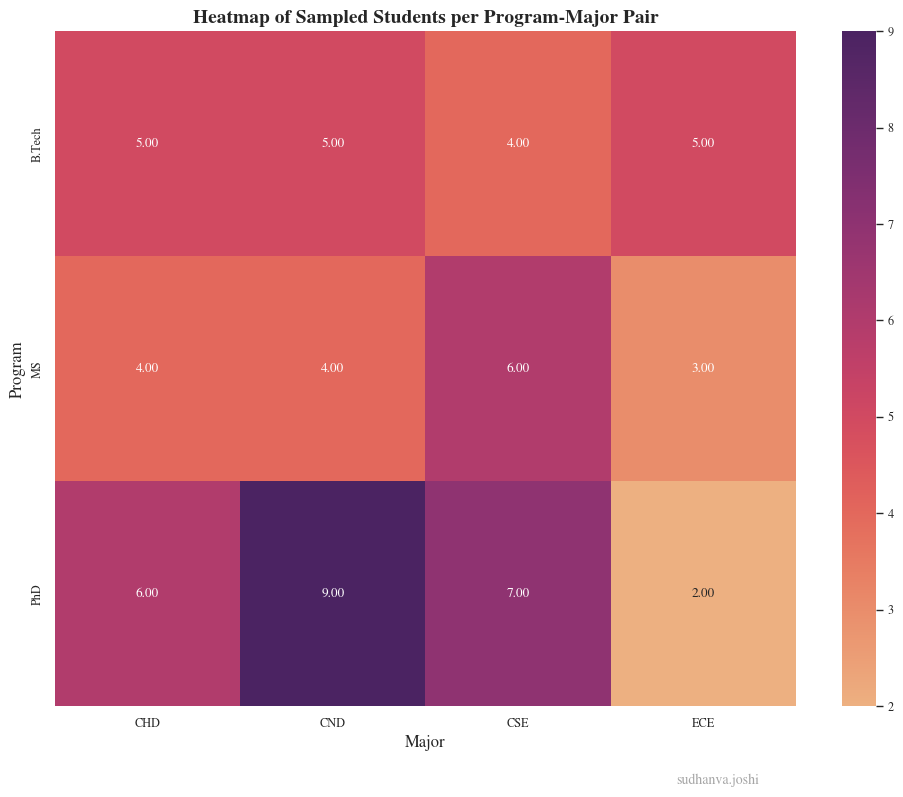

In [10]:
program_major_uniform = dataset.sample_program_major_balanced()
show_program_major_counts_and_heatmap = dataset.show_program_major_counts_and_heatmap(program_major_uniform)